In [45]:
import pandas as pd
import numpy as np
import seaborn as sns
import shap
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
#from sklearn.linear_model import LogisticRegression
#from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import ElasticNetCV
from sklearn.linear_model import Ridge
#from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler

In [46]:
# Load the data

In [47]:
#Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')
Data = Data.iloc[:, 0:]

In [48]:
Data

,Frame Index,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,...,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,1,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,...,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,2,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,...,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,3,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,...,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,4,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,...,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,5,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,...,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,10328,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,...,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10329,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,...,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,10330,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,...,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,10331,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,...,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [49]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10332 entries, 0 to 10331
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Frame Index              10332 non-null  int64  
 1   FPS                      10332 non-null  float64
 2   Frame Duration (ms)      10332 non-null  float64
 3   Min Frame Duration (ms)  10332 non-null  float64
 4   Max Frame Duration (ms)  10332 non-null  float64
 5   Avg Frame Duration (ms)  10332 non-null  float64
 6   Std Dev (ms)             10332 non-null  float64
 7   Entropy Framerate        10332 non-null  float64
 8   MotionToPhotonLatency    10332 non-null  float64
 9   minMtpLatency            10332 non-null  float64
 10  maxMtpLatency            10332 non-null  float64
 11  avgMtpLatency            10332 non-null  float64
 12  StdDev mtpLatency        10332 non-null  float64
 13  mtpEntropy               10332 non-null  float64
 14  currentRotation.x     

In [50]:
Data.head(10)

,Frame Index,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,...,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,1,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,...,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,2,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,...,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,3,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,...,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,4,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,...,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,5,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,...,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
5,6,77.87,12.84,12.65,16.11,13.26,1.50,0.09,12.84,12.84,...,14.32,4.70,0.14,0.34,-0.10,-0.14,0.93,36.49,339.33,336.17
6,7,69.38,14.41,12.65,14.52,13.88,0.88,0.31,14.41,12.84,...,14.37,4.71,0.15,0.33,-0.11,-0.14,0.93,36.22,339.10,336.32
7,8,68.05,14.69,12.65,14.69,14.28,1.12,0.41,14.69,14.41,...,14.53,4.70,0.19,0.33,-0.11,-0.14,0.93,35.86,338.75,336.44
8,9,69.73,14.34,12.65,14.69,14.31,1.01,0.30,14.34,14.34,...,14.45,0.65,0.18,0.33,-0.11,-0.13,0.93,35.46,338.31,336.46
9,10,80.83,12.37,12.37,14.69,13.51,0.90,0.07,12.37,12.37,...,13.60,0.94,0.20,0.33,-0.12,-0.13,0.93,35.04,337.75,336.37


In [51]:
Data.shape

(10332, 21)

In [52]:
# Select input features and target variable

In [53]:
X = Data.iloc[:, 0 :]
X.drop(['FPS', 'Frame Index'], axis=1, inplace=True)

In [54]:
y = Data['FPS']

In [55]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [56]:
#Scale data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [57]:
# Fit a random forest regressor and get the feature importances

In [58]:
rf = RandomForestRegressor()
rf.fit(X_train, y_train)

RandomForestRegressor()

In [59]:
importances = rf.feature_importances_

In [60]:
indices = np.argsort(importances)[::-1]

In [61]:
# Get feature names
feature_names = X.columns

In [62]:
# Get feature names
feature_names = X.columns

In [63]:
# Print feature ranking
print("Feature ranking:")
for f in range(X.shape[1]):
    print("%d. feature %d (%f) - %s" % (f + 1, indices[f], importances[indices[f]], feature_names[indices[f]]))

Feature ranking:
1. feature 0 (0.999777) - Frame Duration (ms)
2. feature 6 (0.000144) - MotionToPhotonLatency
3. feature 1 (0.000052) - Min Frame Duration (ms)
4. feature 7 (0.000007) - minMtpLatency
5. feature 13 (0.000003) - currentRotation.y
6. feature 4 (0.000003) - Std Dev (ms)
7. feature 5 (0.000002) - Entropy Framerate
8. feature 9 (0.000002) - avgMtpLatency
9. feature 8 (0.000002) - maxMtpLatency
10. feature 17 (0.000001) - yaw
11. feature 15 (0.000001) - currentRotation.w
12. feature 16 (0.000001) - pitch
13. feature 2 (0.000001) - Max Frame Duration (ms)
14. feature 3 (0.000001) - Avg Frame Duration (ms)
15. feature 10 (0.000001) - StdDev mtpLatency
16. feature 12 (0.000001) - currentRotation.x
17. feature 11 (0.000000) - mtpEntropy
18. feature 14 (0.000000) - currentRotation.z
19. feature 18 (0.000000) - roll


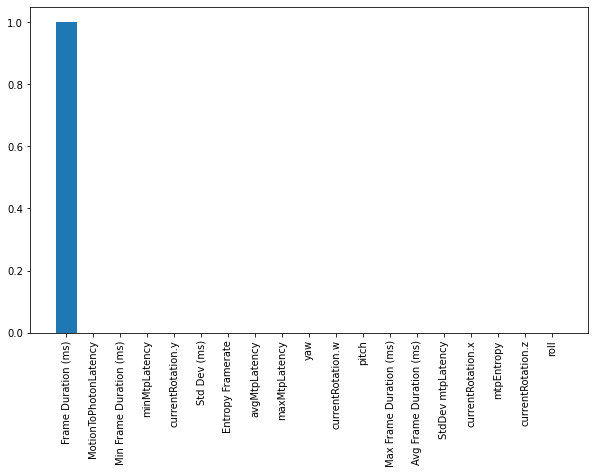

In [64]:
# Plot feature importances
plt.figure(figsize=(10, 6))
plt.bar(range(len(importances)), importances[indices])
plt.xticks(range(len(importances)), feature_names[indices], rotation=90)
plt.show()

In [65]:
# Calculate permutation importances

In [66]:
result_rf = permutation_importance(rf, X_test, y_test, n_repeats=50, random_state=42)

In [67]:
# Print feature ranking
sorted_idx = result_rf.importances_mean.argsort()[::-1]
for i in sorted_idx:
    print(f"{X.columns[i]:<15} {result_rf.importances_mean[i]:.3f} +/- {result_rf.importances_std[i]:.3f}")

Frame Duration (ms) 1.993 +/- 0.043
MotionToPhotonLatency 0.000 +/- 0.000
Min Frame Duration (ms) 0.000 +/- 0.000
minMtpLatency   0.000 +/- 0.000
currentRotation.w 0.000 +/- 0.000
currentRotation.z 0.000 +/- 0.000
StdDev mtpLatency 0.000 +/- 0.000
currentRotation.x 0.000 +/- 0.000
yaw             0.000 +/- 0.000
maxMtpLatency   0.000 +/- 0.000
pitch           0.000 +/- 0.000
roll            0.000 +/- 0.000
Max Frame Duration (ms) -0.000 +/- 0.000
mtpEntropy      -0.000 +/- 0.000
Avg Frame Duration (ms) -0.000 +/- 0.000
avgMtpLatency   -0.000 +/- 0.000
Entropy Framerate -0.000 +/- 0.000
Std Dev (ms)    -0.000 +/- 0.000
currentRotation.y -0.000 +/- 0.000


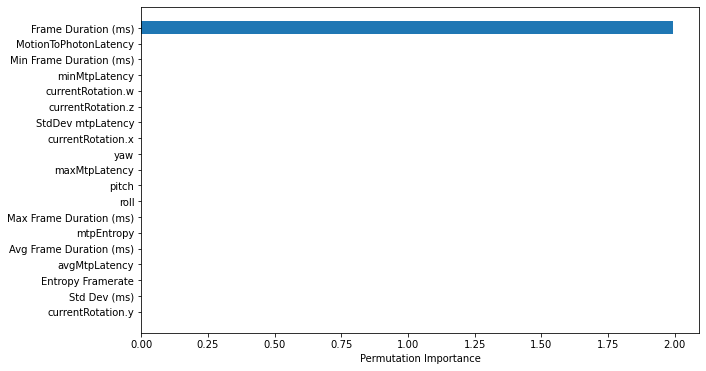

In [68]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_rf.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_rf.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [69]:
# Fit a linear regression model

In [70]:
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [71]:
# Get the coefficient values and feature names
coef_lr = lr.coef_

In [72]:
feature_names = X.columns

In [73]:
'Feature ranking'
for i in range(len(feature_names)):
    print("%s: %f" % (feature_names[i], abs(coef_lr[i])))

Frame Duration (ms): 7.738694
Min Frame Duration (ms): 0.875062
Max Frame Duration (ms): 1.920690
Avg Frame Duration (ms): 16.031349
Std Dev (ms): 2.398773
Entropy Framerate: 3.026054
MotionToPhotonLatency: 3.503911
minMtpLatency: 1.297488
maxMtpLatency: 1.687780
avgMtpLatency: 31.409423
StdDev mtpLatency: 2.361212
mtpEntropy: 6.627882
currentRotation.x: 0.911177
currentRotation.y: 1.438178
currentRotation.z: 1.098318
currentRotation.w: 0.072413
pitch: 0.382757
yaw: 0.459949
roll: 0.027143


In [74]:
# Print the feature importance in order of highest to lowest absolute coefficient values
print("Feature importance:")
sorted_indices = np.argsort(abs(coef_lr))[::-1]
for i in sorted_indices:
    print("%s: %f" % (feature_names[i], abs(coef_lr[i])))

Feature importance:
avgMtpLatency: 31.409423
Avg Frame Duration (ms): 16.031349
Frame Duration (ms): 7.738694
mtpEntropy: 6.627882
MotionToPhotonLatency: 3.503911
Entropy Framerate: 3.026054
Std Dev (ms): 2.398773
StdDev mtpLatency: 2.361212
Max Frame Duration (ms): 1.920690
maxMtpLatency: 1.687780
currentRotation.y: 1.438178
minMtpLatency: 1.297488
currentRotation.z: 1.098318
currentRotation.x: 0.911177
Min Frame Duration (ms): 0.875062
yaw: 0.459949
pitch: 0.382757
currentRotation.w: 0.072413
roll: 0.027143


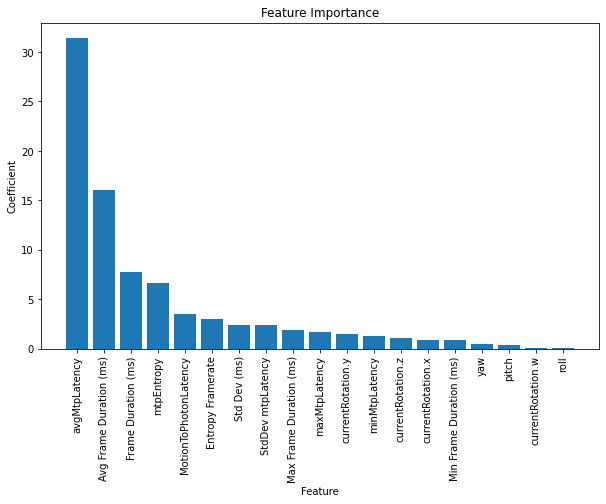

In [75]:
# Plot feature importance in order of highest to lowest absolute coefficient values
sorted_indices = np.argsort(abs(coef_lr))[::-1]
sorted_features = [feature_names[i] for i in sorted_indices]
sorted_coefficients = [abs(coef_lr[i]) for i in sorted_indices]

plt.figure(figsize=(10, 6))
plt.bar(sorted_features, sorted_coefficients)
plt.xticks(rotation=90)
plt.xlabel('Feature')
plt.ylabel('Coefficient')
plt.title('Feature Importance')
plt.show()

In [76]:
# Calculate permutation importances

In [77]:
result_lr = permutation_importance(lr, X_test, y_test, n_repeats=50, random_state=42)

In [78]:
# Print permutation importances
print("Permutation importances:")
for i in result_lr.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_lr.importances_mean[i]))

Permutation importances:
avgMtpLatency: 4.632872
Avg Frame Duration (ms): 1.200852
mtpEntropy: 0.199417
Frame Duration (ms): 0.188532
Entropy Framerate: 0.038698
MotionToPhotonLatency: 0.025077
StdDev mtpLatency: 0.019301
Max Frame Duration (ms): 0.017396
Std Dev (ms): 0.016975
currentRotation.y: 0.008611
maxMtpLatency: 0.006109
minMtpLatency: 0.004784
currentRotation.z: 0.004576
currentRotation.x: 0.004123
Min Frame Duration (ms): 0.003384
yaw: 0.000802
pitch: 0.000218
currentRotation.w: 0.000035
roll: -0.000022


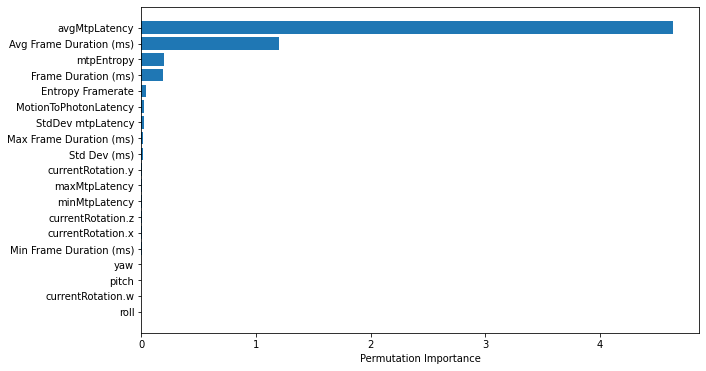

In [79]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_lr.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_lr.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [80]:
#Lasso regression

In [81]:
l_reg = Lasso(alpha=0.1)
l_reg.fit(X_train, y_train)

Lasso(alpha=0.1)

In [82]:
l_reg_abs = abs(l_reg.coef_)

In [83]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature_names': X.columns, 'Importance': l_reg_abs})

In [84]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)

In [85]:
feature_importance

,Feature_names,Importance
9,avgMtpLatency,16.253814
11,mtpEntropy,5.591823
0,Frame Duration (ms),5.242385
5,Entropy Framerate,2.296890
10,StdDev mtpLatency,1.920097
8,maxMtpLatency,1.580405
13,currentRotation.y,1.511121
4,Std Dev (ms),1.085666
7,minMtpLatency,1.074632
6,MotionToPhotonLatency,0.809466


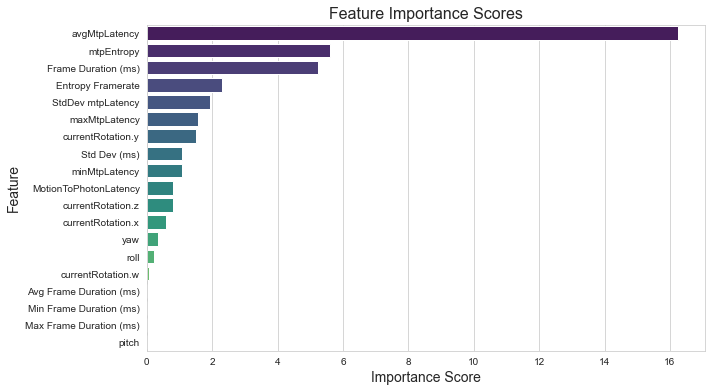

In [86]:
# Create a barplot of the feature importance scores>
plt.figure(figsize=(10, 6))
sns.set_style('whitegrid')
sns.barplot(x='Importance', y='Feature_names', data=feature_importance, palette='viridis')
plt.xlabel('Importance Score', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.title('Feature Importance Scores', fontsize=16)
plt.show()

In [87]:
# Calculate permutation importances

In [88]:
result_l_reg= permutation_importance(l_reg, X_test, y_test, n_repeats=50, random_state=42)

In [89]:
# Print permutation importances
print("Permutation importances:")
for i in result_l_reg.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_l_reg.importances_mean[i]))

Permutation importances:
avgMtpLatency: 1.245936
mtpEntropy: 0.143170
Frame Duration (ms): 0.093355
Entropy Framerate: 0.024151
StdDev mtpLatency: 0.013351
currentRotation.y: 0.010847
maxMtpLatency: 0.006072
minMtpLatency: 0.003350
Std Dev (ms): 0.003254
currentRotation.z: 0.002414
currentRotation.x: 0.001985
yaw: 0.000634
roll: 0.000072
MotionToPhotonLatency: 0.000065
currentRotation.w: 0.000061
pitch: 0.000000
Avg Frame Duration (ms): 0.000000
Max Frame Duration (ms): 0.000000
Min Frame Duration (ms): 0.000000


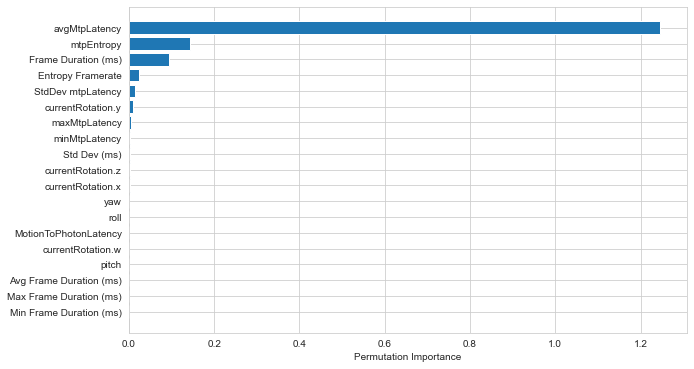

In [90]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_l_reg.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_l_reg.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [91]:
#Elastic Net Feature Importance

In [92]:
# Create Elastic Net object
enet = ElasticNetCV(cv=5, random_state=0)
enet.fit(X_train, y_train)

ElasticNetCV(cv=5, random_state=0)

In [93]:
# Extract feature importance from coefficients
feature_importance = abs(enet.coef_)

In [94]:
# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

In [95]:
# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

In [96]:
# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

In [97]:
# Print the feature importance scores
for feature in sorted_features:
    print(feature[0], ": ", feature[1])

avgMtpLatency :  0.2966508221684578
Frame Duration (ms) :  0.1321289258502115
mtpEntropy :  0.13204930534216214
Avg Frame Duration (ms) :  0.0797585627007913
Entropy Framerate :  0.059990094199042936
Std Dev (ms) :  0.046284043405295426
currentRotation.y :  0.039551507389634956
maxMtpLatency :  0.03683589241553798
StdDev mtpLatency :  0.03668024560910694
MotionToPhotonLatency :  0.03101712741683442
minMtpLatency :  0.02466549138440213
currentRotation.z :  0.022697769736209447
Min Frame Duration (ms) :  0.01831903034028703
currentRotation.x :  0.015431571532109709
yaw :  0.009582958626677334
Max Frame Duration (ms) :  0.007393333669262966
roll :  0.007368885320933905
currentRotation.w :  0.0032569484661640787
pitch :  0.00033748442687807313


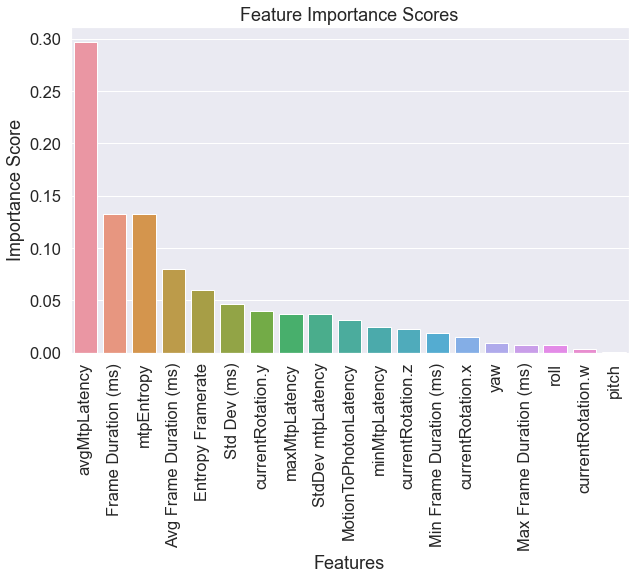

In [98]:
# Create a bar plot of feature importance scores
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
fig, ax = plt.subplots(figsize=(10,6))
sns.barplot(x=[x[0] for x in sorted_features], y=[x[1] for x in sorted_features], ax=ax)
ax.set_title("Feature Importance Scores")
ax.set_xlabel("Features")
ax.set_ylabel("Importance Score")
plt.xticks(rotation=90)
plt.show()

In [99]:
# Calculate permutation importances

In [100]:
result_enet= permutation_importance(enet, X_test, y_test, n_repeats=50, random_state=42)

In [101]:
# Print permutation importances
print("Permutation importances:")
for i in result_enet.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_enet.importances_mean[i]))

Permutation importances:
avgMtpLatency: 0.724213
mtpEntropy: 0.137363
Frame Duration (ms): 0.102142
Avg Frame Duration (ms): 0.052494
Entropy Framerate: 0.028355
currentRotation.y: 0.012539
Std Dev (ms): 0.011002
StdDev mtpLatency: 0.007250
maxMtpLatency: 0.004936
currentRotation.z: 0.003159
Min Frame Duration (ms): 0.002828
minMtpLatency: 0.002631
currentRotation.x: 0.002076
MotionToPhotonLatency: 0.001321
Max Frame Duration (ms): 0.000950
yaw: 0.000651
roll: 0.000163
currentRotation.w: 0.000148
pitch: 0.000015


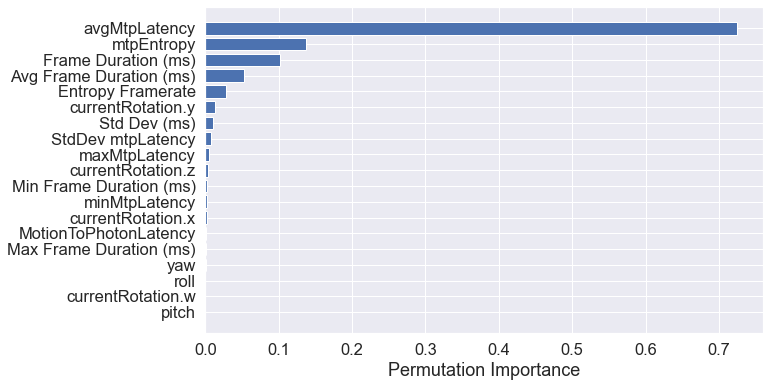

In [102]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_enet.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_enet.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [103]:
# Ridge model

In [104]:
ridge = Ridge()
ridge.fit(X_train, y_train)

Ridge()

In [105]:
# Extract feature importance from coefficients
feature_importance = abs(ridge.coef_)

In [106]:
# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

In [107]:
# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

In [108]:
# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

In [109]:
sorted_features

[('avgMtpLatency', 0.376316606710292),
 ('Avg Frame Duration (ms)', 0.18806419341073133),
 ('Frame Duration (ms)', 0.09416872826816658),
 ('mtpEntropy', 0.08067439924493544),
 ('MotionToPhotonLatency', 0.04239808857989474),
 ('Entropy Framerate', 0.03683540759901029),
 ('Std Dev (ms)', 0.029361526174749405),
 ('StdDev mtpLatency', 0.028570781070757365),
 ('Max Frame Duration (ms)', 0.02305349732690856),
 ('maxMtpLatency', 0.02062750207126861),
 ('currentRotation.y', 0.017693303681734444),
 ('minMtpLatency', 0.01570756357440247),
 ('currentRotation.z', 0.013407233934667561),
 ('currentRotation.x', 0.011033629085016006),
 ('Min Frame Duration (ms)', 0.01063299428506046),
 ('yaw', 0.005574615975224808),
 ('pitch', 0.00451103777355857),
 ('currentRotation.w', 0.0009135329205959972),
 ('roll', 0.00045535831302521675)]

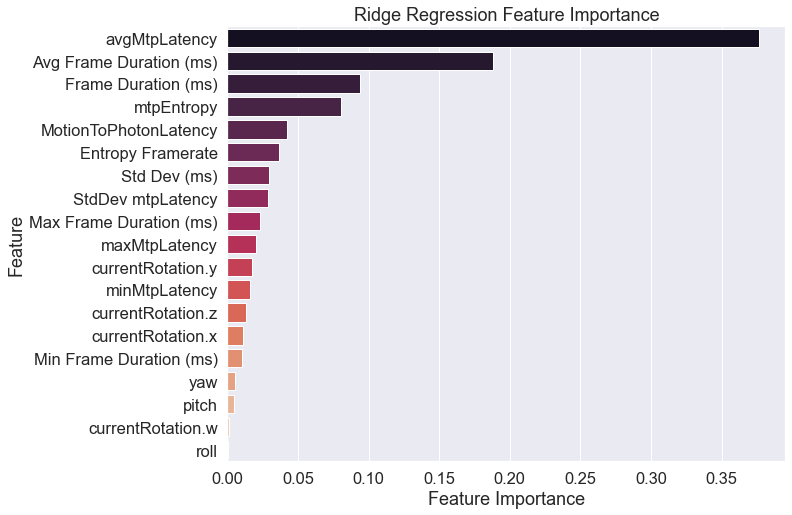

In [110]:
plt.figure(figsize = (10, 8))
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
sns.barplot(x=[x[1] for x in sorted_features], y=[x[0] for x in sorted_features], palette="rocket")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Ridge Regression Feature Importance")
plt.show()

In [111]:
# Calculate permutation importances

In [112]:
result_ridge= permutation_importance(ridge, X_test, y_test, n_repeats=50, random_state=42)

In [113]:
# Print permutation importances
print("Permutation importances:")
for i in result_ridge.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_ridge.importances_mean[i]))

Permutation importances:
avgMtpLatency: 4.445216
Avg Frame Duration (ms): 1.104630
mtpEntropy: 0.197423
Frame Duration (ms): 0.186721
Entropy Framerate: 0.038393
MotionToPhotonLatency: 0.024442
StdDev mtpLatency: 0.018846
Std Dev (ms): 0.017033
Max Frame Duration (ms): 0.016806
currentRotation.y: 0.008742
maxMtpLatency: 0.006099
minMtpLatency: 0.004672
currentRotation.z: 0.004545
currentRotation.x: 0.004039
Min Frame Duration (ms): 0.003342
yaw: 0.000786
pitch: 0.000190
currentRotation.w: 0.000038
roll: -0.000029


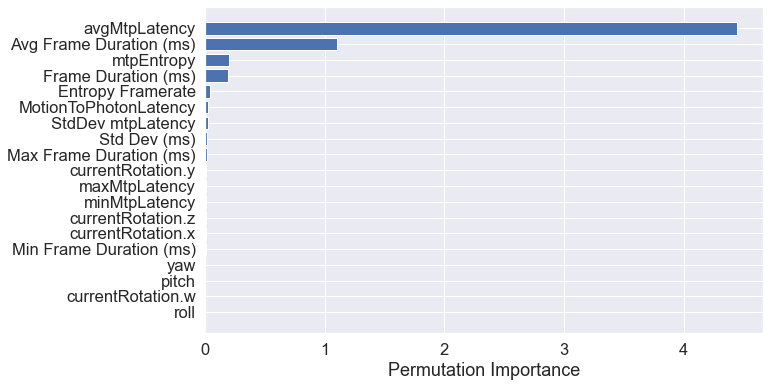

In [114]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_ridge.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_ridge.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()